

 Name: LAVISH  Roll No : 1024170441  Group : 3Q41

### Setup: install libraries and download NLTK data

In [1]:

!pip install -q nltk scikit-learn textblob vaderSentiment wordcloud matplotlib tensorflow

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'vader_lexicon']:
    nltk.download(pkg, quiet=True)


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\gargl\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


---
## Q1. Basic Text Preprocessing


In [2]:
paragraph = """Natural Language Processing (NLP) is a branch of Artificial Intelligence that helps computers understand, interpret, and process human language. It allows machines to communicate with humans using text and speech. NLP is used in applications such as chatbots, language translation, voice assistants, and sentiment analysis. It involves techniques like tokenization, stemming, lemmatization, and stop-word removal. These techniques help computers process and analyze large amounts of text data. Overall, NLP makes human-computer interaction easier, faster, and more effective"""
print(paragraph)

Natural Language Processing (NLP) is a branch of Artificial Intelligence that helps computers understand, interpret, and process human language. It allows machines to communicate with humans using text and speech. NLP is used in applications such as chatbots, language translation, voice assistants, and sentiment analysis. It involves techniques like tokenization, stemming, lemmatization, and stop-word removal. These techniques help computers process and analyze large amounts of text data. Overall, NLP makes human-computer interaction easier, faster, and more effective


**1. Convert to lowercase and remove punctuation using `re`**

In [3]:
import re
lower_text = paragraph.lower()
clean_text = re.sub(r'[^\w\s]', '', lower_text)   # remove punctuation
clean_text = re.sub(r'\s+', ' ', clean_text).strip() # tidy up whitespace
print(clean_text)

natural language processing nlp is a branch of artificial intelligence that helps computers understand interpret and process human language it allows machines to communicate with humans using text and speech nlp is used in applications such as chatbots language translation voice assistants and sentiment analysis it involves techniques like tokenization stemming lemmatization and stopword removal these techniques help computers process and analyze large amounts of text data overall nlp makes humancomputer interaction easier faster and more effective


**2. Tokenize into words and sentences**

In [4]:
from nltk.tokenize import word_tokenize, sent_tokenize

sentences = sent_tokenize(paragraph)          # sentences from the ORIGINAL text (punctuation needed)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(i, s.strip())

words = word_tokenize(clean_text)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
1 Natural Language Processing (NLP) is a branch of Artificial Intelligence that helps computers understand, interpret, and process human language.
2 It allows machines to communicate with humans using text and speech.
3 NLP is used in applications such as chatbots, language translation, voice assistants, and sentiment analysis.
4 It involves techniques like tokenization, stemming, lemmatization, and stop-word removal.
5 These techniques help computers process and analyze large amounts of text data.
6 Overall, NLP makes human-computer interaction easier, faster, and more effective

Number of words: 77
['natural', 'language', 'processing', 'nlp', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence', 'that', 'helps', 'computers', 'understand', 'interpret', 'and', 'process', 'human', 'language', 'it', 'allows', 'machines', 'to', 'communicate', 'with', 'humans', 'using', 'text', 'and', 'speech', 'nlp', 'is', 'used', 'in', 'applications', 'such', 'as', 'chatbots', '

**3. `split()` vs `word_tokenize()`**

In [5]:
sample = "Natural Language Processing is useful for text analysis. It helps computers understand human language"
print("split()        :", sample.split())
print("word_tokenize():", word_tokenize(sample))

print("\nOn our paragraph:")
print("split() count         :", len(paragraph.split()))
print("word_tokenize() count :", len(word_tokenize(paragraph)))

split()        : ['Natural', 'Language', 'Processing', 'is', 'useful', 'for', 'text', 'analysis.', 'It', 'helps', 'computers', 'understand', 'human', 'language']
word_tokenize(): ['Natural', 'Language', 'Processing', 'is', 'useful', 'for', 'text', 'analysis', '.', 'It', 'helps', 'computers', 'understand', 'human', 'language']

On our paragraph:
split() count         : 77
word_tokenize() count : 95


**4. Remove stopwords (NLTK list)**

In [6]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [w for w in words if w not in stop_words]
print("Before:", len(words), " After:", len(filtered_words))
print(filtered_words)

Before: 77  After: 56
['natural', 'language', 'processing', 'nlp', 'branch', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'interpret', 'process', 'human', 'language', 'allows', 'machines', 'communicate', 'humans', 'using', 'text', 'speech', 'nlp', 'used', 'applications', 'chatbots', 'language', 'translation', 'voice', 'assistants', 'sentiment', 'analysis', 'involves', 'techniques', 'like', 'tokenization', 'stemming', 'lemmatization', 'stopword', 'removal', 'techniques', 'help', 'computers', 'process', 'analyze', 'large', 'amounts', 'text', 'data', 'overall', 'nlp', 'makes', 'humancomputer', 'interaction', 'easier', 'faster', 'effective']


**5. Word frequency distribution (excluding stopwords)**

[('language', 3), ('nlp', 3), ('computers', 2), ('process', 2), ('text', 2), ('techniques', 2), ('natural', 1), ('processing', 1), ('branch', 1), ('artificial', 1)]


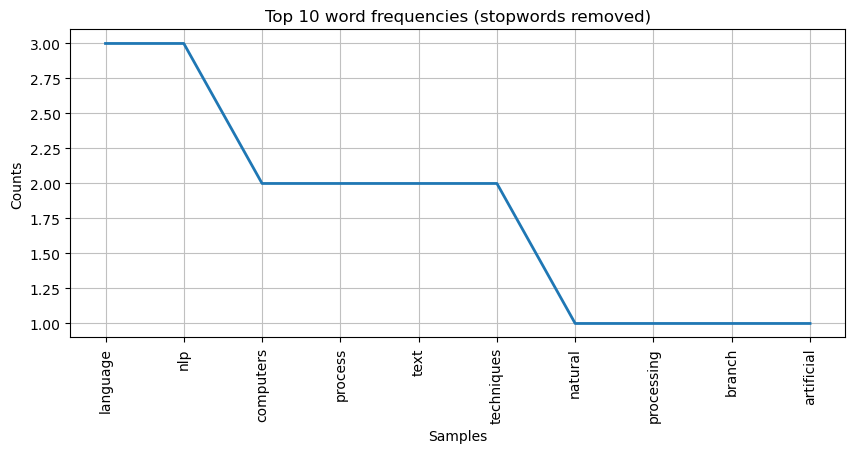

In [7]:
from nltk import FreqDist
import matplotlib.pyplot as plt

fdist = FreqDist(filtered_words)
print(fdist.most_common(10))

plt.figure(figsize=(10, 4))
fdist.plot(10, title="Top 10 word frequencies (stopwords removed)")
plt.show()

---
## Q2. Stemming and Lemmatization (same paragraph)

**1. Extract alphabetic words using `re.findall()`**

In [8]:
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
print(len(alpha_words), alpha_words)

79 ['natural', 'language', 'processing', 'nlp', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence', 'that', 'helps', 'computers', 'understand', 'interpret', 'and', 'process', 'human', 'language', 'it', 'allows', 'machines', 'to', 'communicate', 'with', 'humans', 'using', 'text', 'and', 'speech', 'nlp', 'is', 'used', 'in', 'applications', 'such', 'as', 'chatbots', 'language', 'translation', 'voice', 'assistants', 'and', 'sentiment', 'analysis', 'it', 'involves', 'techniques', 'like', 'tokenization', 'stemming', 'lemmatization', 'and', 'stop', 'word', 'removal', 'these', 'techniques', 'help', 'computers', 'process', 'and', 'analyze', 'large', 'amounts', 'of', 'text', 'data', 'overall', 'nlp', 'makes', 'human', 'computer', 'interaction', 'easier', 'faster', 'and', 'more', 'effective']


**2. Remove stopwords**

In [9]:
no_stop = [w for w in alpha_words if w not in stop_words]
print(len(no_stop), no_stop)

58 ['natural', 'language', 'processing', 'nlp', 'branch', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'interpret', 'process', 'human', 'language', 'allows', 'machines', 'communicate', 'humans', 'using', 'text', 'speech', 'nlp', 'used', 'applications', 'chatbots', 'language', 'translation', 'voice', 'assistants', 'sentiment', 'analysis', 'involves', 'techniques', 'like', 'tokenization', 'stemming', 'lemmatization', 'stop', 'word', 'removal', 'techniques', 'help', 'computers', 'process', 'analyze', 'large', 'amounts', 'text', 'data', 'overall', 'nlp', 'makes', 'human', 'computer', 'interaction', 'easier', 'faster', 'effective']


**3. Stemming with PorterStemmer**

In [10]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in no_stop]
print(stemmed)

['natur', 'languag', 'process', 'nlp', 'branch', 'artifici', 'intellig', 'help', 'comput', 'understand', 'interpret', 'process', 'human', 'languag', 'allow', 'machin', 'commun', 'human', 'use', 'text', 'speech', 'nlp', 'use', 'applic', 'chatbot', 'languag', 'translat', 'voic', 'assist', 'sentiment', 'analysi', 'involv', 'techniqu', 'like', 'token', 'stem', 'lemmat', 'stop', 'word', 'remov', 'techniqu', 'help', 'comput', 'process', 'analyz', 'larg', 'amount', 'text', 'data', 'overal', 'nlp', 'make', 'human', 'comput', 'interact', 'easier', 'faster', 'effect']


**4. Lemmatization with WordNetLemmatizer**

In [11]:
from nltk.stem import WordNetLemmatizer
lem = WordNetLemmatizer()
lemmatized_noun = [lem.lemmatize(w) for w in no_stop]            # default POS = noun
lemmatized_verb = [lem.lemmatize(w, pos='v') for w in no_stop]   # treating words as verbs
print("Noun lemmas:", lemmatized_noun)
print("Verb lemmas:", lemmatized_verb)

Noun lemmas: ['natural', 'language', 'processing', 'nlp', 'branch', 'artificial', 'intelligence', 'help', 'computer', 'understand', 'interpret', 'process', 'human', 'language', 'allows', 'machine', 'communicate', 'human', 'using', 'text', 'speech', 'nlp', 'used', 'application', 'chatbots', 'language', 'translation', 'voice', 'assistant', 'sentiment', 'analysis', 'involves', 'technique', 'like', 'tokenization', 'stemming', 'lemmatization', 'stop', 'word', 'removal', 'technique', 'help', 'computer', 'process', 'analyze', 'large', 'amount', 'text', 'data', 'overall', 'nlp', 'make', 'human', 'computer', 'interaction', 'easier', 'faster', 'effective']
Verb lemmas: ['natural', 'language', 'process', 'nlp', 'branch', 'artificial', 'intelligence', 'help', 'computers', 'understand', 'interpret', 'process', 'human', 'language', 'allow', 'machine', 'communicate', 'humans', 'use', 'text', 'speech', 'nlp', 'use', 'applications', 'chatbots', 'language', 'translation', 'voice', 'assistants', 'sentime

**5. Comparison**

In [12]:
import pandas as pd
df = pd.DataFrame({'Original': no_stop, 'Stemmed': stemmed,
                   'Lemma (noun)': lemmatized_noun, 'Lemma (verb)': lemmatized_verb})
df[df['Original'] != df['Stemmed']].reset_index(drop=True)

,Original,Stemmed,Lemma (noun),Lemma (verb)
0,natural,natur,natural,natural
1,language,languag,language,language
2,processing,process,processing,process
3,artificial,artifici,artificial,artificial
4,intelligence,intellig,intelligence,intelligence
5,helps,help,help,help
6,computers,comput,computer,computers
7,language,languag,language,language
8,allows,allow,allows,allow
9,machines,machin,machine,machine


---
## Q3. Bag of Words and TF-IDF on 3 short texts

In [13]:
texts = [
    "I love learning new things.",
    "Natural Language Processing is very useful.",
    "AI helps students understand difficult topics."
]
for i, t in enumerate(texts, 1): print(f"Text {i}: {t}")

Text 1: I love learning new things.
Text 2: Natural Language Processing is very useful.
Text 3: AI helps students understand difficult topics.


**1. Bag of Words with CountVectorizer**

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(),
                      index=['Text 1', 'Text 2', 'Text 3'])
bow_df

,ai,difficult,helps,language,learning,love,natural,new,processing,students,things,topics,understand,useful
Text 1,0,0,0,0,1,1,0,1,0,0,1,0,0,0
Text 2,0,0,0,1,0,0,1,0,1,0,0,0,0,1
Text 3,1,1,1,0,0,0,0,0,0,1,0,1,1,0


**2. TF-IDF with TfidfVectorizer**

In [15]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray().round(3), columns=tfidf.get_feature_names_out(),
                        index=['Text 1', 'Text 2', 'Text 3'])
tfidf_df

,ai,difficult,helps,language,learning,love,natural,new,processing,students,things,topics,understand,useful
Text 1,0.000,0.000,0.000,0.0,0.5,0.5,0.0,0.5,0.0,0.000,0.5,0.000,0.000,0.0
Text 2,0.000,0.000,0.000,0.5,0.0,0.0,0.5,0.0,0.5,0.000,0.0,0.000,0.000,0.5
Text 3,0.408,0.408,0.408,0.0,0.0,0.0,0.0,0.0,0.0,0.408,0.0,0.408,0.408,0.0


**3. Top 3 keywords per text**

In [16]:
import numpy as np
features = tfidf.get_feature_names_out()
for i in range(len(texts)):
    row = tfidf_matrix[i].toarray().flatten()
    top3 = row.argsort()[::-1][:3]
    print(f"Text {i+1} top 3 keywords:", [(features[j], round(row[j], 3)) for j in top3])

Text 1 top 3 keywords: [('things', np.float64(0.5)), ('new', np.float64(0.5)), ('love', np.float64(0.5))]
Text 2 top 3 keywords: [('useful', np.float64(0.5)), ('processing', np.float64(0.5)), ('language', np.float64(0.5))]
Text 3 top 3 keywords: [('understand', np.float64(0.408)), ('topics', np.float64(0.408)), ('students', np.float64(0.408))]


---
## Q4. Jaccard and Cosine Similarity (Cognitive Computing vs Emotion Recognition Technology)

In [17]:
text_a = """Cognitive computing helps machines think like humans.
It understands information using AI.
It learns from data and past experiences.
It helps in making intelligent decisions."""

text_b = """Emotion recognition detects human emotions.
It analyzes facial expressions and voice.
It uses machine learning and NLP.
It helps computers understand human feelings."""

**1. Preprocess and tokenize**

In [19]:
def preprocess(text):
    text = re.sub(r'[^\w\s]', '', text.lower())
    tokens = word_tokenize(text)
    return [lem.lemmatize(t) for t in tokens if t not in stop_words and t.isalpha()]

tokens_a = preprocess(text_a)
tokens_b = preprocess(text_b)
print("Cogntive   :", tokens_a)
print("Emotion:", tokens_b)

Cogntive   : ['cognitive', 'computing', 'help', 'machine', 'think', 'like', 'human', 'understands', 'information', 'using', 'ai', 'learns', 'data', 'past', 'experience', 'help', 'making', 'intelligent', 'decision']
Emotion: ['emotion', 'recognition', 'detects', 'human', 'emotion', 'analyzes', 'facial', 'expression', 'voice', 'us', 'machine', 'learning', 'nlp', 'help', 'computer', 'understand', 'human', 'feeling']


**2a. Jaccard similarity (sets)**

In [20]:
set_a, set_b = set(tokens_a), set(tokens_b)
intersection = set_a & set_b
union = set_a | set_b
jaccard = len(intersection) / len(union)
print("Common words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

Common words: {'help', 'machine', 'human'}
Jaccard Similarity: 0.0968


**2b. Cosine similarity (TfidfVectorizer + cosine_similarity)**

In [21]:
from sklearn.metrics.pairwise import cosine_similarity
docs = [' '.join(tokens_a), ' '.join(tokens_b)]
tv = TfidfVectorizer()
vecs = tv.fit_transform(docs)
cos = cosine_similarity(vecs[0], vecs[1])[0][0]
print("Cosine Similarity:", round(cos, 4))

Cosine Similarity: 0.1366


**2c. Analysis:** Cosine Similarity (0.1366) gives better insights because it considers the frequency of words and overall text direction, while Jaccard Similarity (0.0968) only compares common unique words. Therefore, cosine similarity is more suitable for comparing the overall textual similarity in this case.

---
## Q5. Sentiment Analysis (TextBlob / VADER) and Word Cloud

In [22]:
reviews = [
    "Google Gemini is an excellent AI tool that provides quick and accurate answers. It is easy to use and helps students with learning, research, and problem-solving. Its features save time and improve productivity. Overall, I am very satisfied with this product and recommend it to others."
]

**1. Polarity and subjectivity (TextBlob)**

In [23]:
from textblob import TextBlob
import pandas as pd

rows = []
for r in reviews:
    tb = TextBlob(r)
    rows.append({'Review': r, 'Polarity': round(tb.sentiment.polarity, 3),
                 'Subjectivity': round(tb.sentiment.subjectivity, 3)})
df_sent = pd.DataFrame(rows)
df_sent

,Review,Polarity,Subjectivity
0,Google Gemini is an excellent AI tool that pro...,0.469,0.661


**2. Classify into Positive / Negative / Neutral** (polarity > 0.05 → Positive, < -0.05 → Negative, else Neutral)

In [24]:
def classify(p):
    if p > 0.05: return 'Positive'
    elif p < -0.05: return 'Negative'
    return 'Neutral'

df_sent['Sentiment'] = df_sent['Polarity'].apply(classify)
pd.set_option('display.max_colwidth', 80)
display(df_sent[['Review', 'Polarity', 'Subjectivity', 'Sentiment']])
print(df_sent['Sentiment'].value_counts())

# Optional: VADER comparison
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
df_sent['VADER_compound'] = [vader.polarity_scores(r)['compound'] for r in reviews]
df_sent['VADER_label'] = df_sent['VADER_compound'].apply(
    lambda c: 'Positive' if c >= 0.05 else ('Negative' if c <= -0.05 else 'Neutral'))
df_sent[['Review', 'Sentiment', 'VADER_compound', 'VADER_label']]

,Review,Polarity,Subjectivity,Sentiment
0,Google Gemini is an excellent AI tool that provides quick and accurate answe...,0.469,0.661,Positive


Sentiment
Positive    1
Name: count, dtype: int64


,Review,Sentiment,VADER_compound,VADER_label
0,Google Gemini is an excellent AI tool that provides quick and accurate answe...,Positive,0.9633,Positive


**3. Word cloud of all positive reviews**

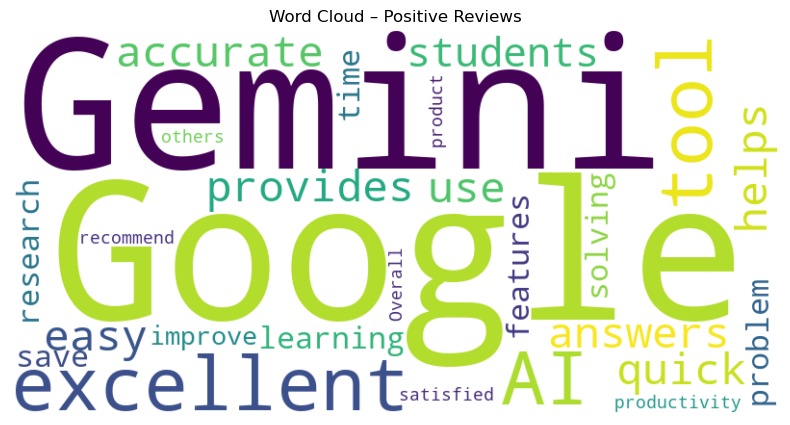

In [25]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = ' '.join(df_sent[df_sent['Sentiment'] == 'Positive']['Review'])
wc = WordCloud(width=800, height=400, background_color='white',
               stopwords=set(stopwords.words('english'))).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud – Positive Reviews')
plt.show()

---
## Q6. Text Generation using LSTM (Keras)

In [26]:
training_text = """Google Gemini is an excellent AI-powered tool that makes learning and daily tasks easier. It provides quick answers, useful explanations, and creative ideas. The interface is simple and user-friendly, making it suitable for students and professionals. I really like its ability to understand questions and generate meaningful responses. It saves time and helps users improve their productivity. Sometimes, its answers may contain incorrect information, so verification is important. Overall, Google Gemini is a helpful and innovative technology that improves the learning experience. I highly recommend it to students who want to explore artificial intelligence and make their work easier."""
print(len(training_text.split()), "words")

99 words


**1. Tokenize with Keras `Tokenizer()`**

In [27]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text.lower()])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)
print(list(tokenizer.word_index.items())[:10])

Vocabulary size: 76
[('and', 1), ('is', 2), ('it', 3), ('to', 4), ('google', 5), ('gemini', 6), ('that', 7), ('learning', 8), ('easier', 9), ('answers', 10)]


**2. Create input sequences and build the LSTM model**

In [28]:
# n-gram sequences built line by line (sentence by sentence)
input_sequences = []
for sentence in training_text.lower().split('.'):
    if not sentence.strip():
        continue
    token_list = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_len = max(len(s) for s in input_sequences)
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_len, padding='pre'))

X = input_sequences[:, :-1]
y = to_categorical(input_sequences[:, -1], num_classes=total_words)
print("X shape:", X.shape, " y shape:", y.shape)

model = Sequential([
    Embedding(total_words, 50, input_length=max_len - 1),
    LSTM(128),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

X shape: (93, 16)  y shape: (93, 76)


c:\Users\gargl\miniconda3\envs\pyenv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**3. Train the model and generate text from seed words**

In [30]:
history = model.fit(X, y, epochs=250, verbose=0)
print("Final training accuracy:", round(history.history['accuracy'][-1], 3))

def generate_text(seed_text, next_words=8):
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([seed_text])[0]
        seq = pad_sequences([seq], maxlen=max_len - 1, padding='pre')
        predicted = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
        word = tokenizer.index_word.get(predicted, '')
        seed_text += ' ' + word
    return seed_text

for seed in ['Excellent', 'Helpful', 'Innovative']:
    print(generate_text(seed, 8))

Final training accuracy: 0.978
Excellent saves time and helps users improve their productivity
Helpful google gemini is a helpful and innovative technology
Innovative interface is simple and user friendly making it
